# R-KalWeNN no California Housing

Mesma estrutura do notebook 08, aplicada ao California Housing do StatLib, que
vem no `sklearn.datasets.fetch_california_housing`.

| seção | conteúdo |
|---|---|
| 1 | configuração |
| 2 | definições: três termômetros, médias, endereçamento, ReW, R-KalWeNN |
| 3 | dados e análise |
| 4 | Regression WiSARD: termômetro, tamanho, address e média |
| 5 | modelos de comparação |
| 6 | R-KalWeNN |
| 7 | gráficos |

**Três diferenças em relação ao notebook 08.** Aqui há **três** termômetros no
grid da ReW, `simple`, `dynamic` e `distributive`, e não um só. O dataset tem 8
atributos em vez de 90, então a retina é `8 x therm` e o termômetro precisa ser
muito maior para dar um número razoável de RAM nodes, o que a seção 3.5 mostra.
E não existe protocolo de divisão prescrito, então usamos `train_test_split`
embaralhado com semente fixa, ao contrário da divisão posicional do UCI.

Não há baseline publicado do Lusquino para este dataset: a tese cobre
`calcofi`, `houseprice`, `kdd` e `parkison`. As referências são os chutes
triviais e os quatro modelos da seção 5.

---
# Seção 1 — Configuração

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_KAL, COR_REW, COR_REF = "#2F6B6A", "#B4674D", "#8A8F98"
CORES_SERIE = [COR_KAL, COR_REW, "#6B7A8F", "#A8894C", "#7D6B8F"]

# ── divisão ──────────────────────────────────────────────────────────────────
# O California Housing não tem protocolo de divisão prescrito, ao contrário do
# YearPredictionMSD. Usamos train_test_split embaralhado, que é o que a
# literatura desse dataset faz, com semente fixa e registrada.
FRACAO_TESTE = 0.20
SEED_DIVISAO = 0
SEED_MAPPING = 0

print(f"divisão: {100*(1-FRACAO_TESTE):.0f}% treino / {100*FRACAO_TESTE:.0f}% teste, "
      f"embaralhada, semente {SEED_DIVISAO}")


divisão: 80% treino / 20% teste, embaralhada, semente 0


---
# Seção 2 — Definições

Tudo definido aqui dentro, sem importar de `rew.py`, como nos notebooks 06 e 08.

## 2.1 Os três termômetros

O que muda entre eles é onde os limiares ficam, e a nomenclatura segue o
`wisardpkg`: `SimpleThermometer(thermometerSize, minimum, maximum)` recebe
escalares, logo uma faixa única para todos os atributos, e
`DynamicThermometer(sizes, minimum, maximum)` recebe listas, logo uma faixa por
atributo.

| termômetro | onde ficam os limiares |
|---|---|
| `simple` | igualmente espaçados numa faixa `[min, max]` única, compartilhada por todos os atributos |
| `dynamic` | igualmente espaçados numa faixa `[min_j, max_j]` própria de cada atributo |
| `distributive` | um por percentil do atributo, cada faixa com a mesma quantidade de exemplos |

O `distributive` é o Distributive Thermometer de Bacellar et al., ESANN 2022,
citado no código. Ele foi o que resolveu o problema de bits constantes no
notebook 08.

In [3]:
# ═══════════════════════════ OS TRÊS TERMÔMETROS ════════════════════════════
# Todos codificam um atributo contínuo em `resolution` bits unários, com o bit
# j valendo 1 quando o valor passa do limiar j. O que muda entre eles é ONDE os
# limiares ficam.
#
#   Simple        uma faixa única [min, max] sobre TODOS os atributos juntos.
#                 É o SimpleThermometer(thermometerSize, minimum, maximum) do
#                 wisardpkg, que recebe um mínimo e um máximo escalares.
#
#   Dynamic       uma faixa própria [min_j, max_j] por atributo, espaçamento
#                 linear dentro dela. É o DynamicThermometer(sizes, minimum,
#                 maximum) do wisardpkg, que recebe listas.
#
#   Distributive  um limiar por percentil do atributo, de modo que cada faixa
#                 receba a mesma quantidade de exemplos de treino.
#                 Bacellar, Susskind, Villon, Miranda, de Araújo, Dutra,
#                 Breternitz Jr., John, Lima e França. Distributive Thermometer:
#                 A New Unary Encoding for Weightless Neural Networks.
#                 ESANN 2022, Bruges, p. 31-36.
#                 https://www.esann.org/sites/default/files/proceedings/2022/ES2022-94.pdf


class Thermometer:
    """Guarda os limiares de um atributo e codifica em unário."""

    def __init__(self, limiares):
        self.limiares = np.asarray(limiares, dtype=float)
        self.resolution = len(self.limiares)

    def encode(self, coluna):
        return (np.asarray(coluna, dtype=float)[:, None]
                > self.limiares[None, :]).astype(np.uint8)


def _linear(mn, mx, resolution):
    """`resolution` limiares igualmente espaçados dentro de (mn, mx]."""
    return mn + (mx - mn) * np.arange(1, resolution + 1) / resolution


def build_simple(X, resolution):
    """Uma faixa só, compartilhada por todos os atributos."""
    mn, mx = float(X.min()), float(X.max())
    lim = _linear(mn, mx, resolution)
    return [Thermometer(lim) for _ in range(X.shape[1])]


def build_dynamic(X, resolution):
    """Uma faixa por atributo, espaçamento linear dentro dela."""
    mn, mx = X.min(axis=0), X.max(axis=0)
    return [Thermometer(_linear(mn[j], mx[j], resolution))
            for j in range(X.shape[1])]


def build_distributive(X, resolution):
    """Um limiar por percentil, `resolution`+1 faixas de mesma probabilidade."""
    qs = np.linspace(0.0, 100.0, resolution + 2)[1:-1]
    return [Thermometer(np.percentile(X[:, j], qs)) for j in range(X.shape[1])]


TERMOMETROS = {"simple": build_simple,
               "dynamic": build_dynamic,
               "distributive": build_distributive}


def apply_encoders(X, encoders):
    return np.concatenate([enc.encode(X[:, j]) for j, enc in enumerate(encoders)],
                          axis=1)


def bytes_limiares(encoders):
    """Bytes que os limiares ocupam. O simple guarda um vetor só, os outros um
    por atributo, e isso entra na conta de memória do modelo."""
    unicos = {id(e.limiares): e.limiares.nbytes for e in encoders}
    return sum(unicos.values())


print("termômetros:", ", ".join(TERMOMETROS))


termômetros: simple, dynamic, distributive


## 2.2 As médias

Duas famílias, como no notebook 08. A da ReW divide pelo contador; a do R-KalWeNN, com prefixo `K`, multiplica pela confiança e normaliza por `sum(c)`.

In [5]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    """log((1 + soma de e^mu) / m), com o `1 +` da referência preservado.

    Calculada de forma estável: com mu na escala do ano, e^2000 é `inf` em
    float64, cujo limite é e^709. Pondo mx = max(mu),

        log((1 + soma e^mu)/m) = mx + log(e^-mx + soma e^(mu-mx)) - log(m)

    que é a mesma expressão e não estoura. Confere com a forma direta até o
    último bit onde a forma direta ainda funciona.
    """
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        mus = [y / c for c, y in output_rams if c != 0]
        if not mus:
            return 0.0
        mus = np.asarray(mus, dtype=float); mx = mus.max()
        return float(mx + np.log(np.exp(-mx) + np.exp(mus - mx).sum())
                     - np.log(len(mus)))


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [6]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaK:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaK"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class KSimpleMean(MediaK):
    nome = "K-SimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class KPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-PowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class KHarmonicMean(MediaK):
    nome = "K-HarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class KHarmonicPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-HarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class KExponentialMean(MediaK):
    """log(soma c e^y / soma c), calculada de forma estável.

    Pondo mx = max(y), vira mx + log(soma c e^(y-mx) / soma c), que é a mesma
    expressão e não estoura quando y está na escala do ano.
    """
    nome = "K-ExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        mx = max(y for _, y in pares)
        return float(mx + np.log(sum(c * np.exp(y - mx) for c, y in pares) / sc))


class KMedian(MediaK):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "K-Median"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"K-SimpleMean": KSimpleMean(), "K-PowerMean(2)": KPowerMean(2),
            "K-HarmonicMean": KHarmonicMean(),
            "K-HarmonicPower(2)": KHarmonicPowerMean(2),
            "K-ExponentialMean": KExponentialMean(), "K-Median": KMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: K-SimpleMean, K-PowerMean(2), K-HarmonicMean, K-HarmonicPower(2), K-ExponentialMean, K-Median


## 2.3 Endereçamento

In [7]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def _dtype_addr(self):
        """Menor inteiro que cabe um endereço de `address_size` bits."""
        if self.address_size <= 8:
            return np.uint8
        if self.address_size <= 16:
            return np.uint16
        return np.int64

    def enderecos(self, Xb, bloco=20_000):
        """(n, retina) uint8 -> (n, n_rams).

        Em blocos de linhas: `Xb[:, mapping] * pesos` tem forma
        (n, n_rams, address_size), ou seja n x retina_bits elementos, e num
        único array isso passa de 8 GB com o treino completo. O bloco limita o
        intermediário e o tipo de saída é o menor que cabe o endereço.
        """
        Xb = np.asarray(Xb, dtype=np.uint8)
        dt = self._dtype_addr()
        pesos = self._pesos.astype(dt)
        out = np.empty((len(Xb), self.n_rams), dtype=dt)
        for i in range(0, len(Xb), bloco):
            j = min(i + bloco, len(Xb))
            out[i:j] = (Xb[i:j][:, self.mapping] * pesos).sum(axis=2, dtype=dt)
        return out


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


## 2.4 Regression WiSARD

In [8]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida")

RegressionWiSARD definida


## 2.5 R-KalWeNN e memória esparsa

In [9]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        # int32 explícito: `empty_like(addr_fit)` herdaria o tipo do endereço,
        # que agora é uint8, e os slots vão muito além de 255.
        self.slots_fit = np.empty(addr_fit.shape, dtype=np.int32)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int32)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

IndiceRK definido


In [10]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    ATUALIZAÇÃO DE c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas,
                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    ATUALIZAÇÃO DE y   p_y cresce q_y uma vez por acesso, e a correção
                       roda só no acesso. Célula não acessada não é tocada
                       por nenhuma das duas.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else KSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        for i in ordem:
            s = idx.slots_fit[i]
            pp = PY[s] + self.q_y                      # predição, uma por visita
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

RKalWeNN definida (memória esparsa)


## 2.6 Avaliação vetorizada das médias

In [11]:
def coleta(modelo, slots):
    """(C, Y, V) de (n, n_rams) a partir dos slots do conjunto avaliado."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


def medias_vetorizadas(C, Y, V, nomes):
    """As seis médias ponderadas, em forma de redução sobre matrizes."""
    Cm = np.where(V, C, 0.0)
    sc = Cm.sum(1)
    ok = sc > 0
    V2 = V & (Y > 0)                       # harmônicas exigem y > 0
    Cm2 = np.where(V2, C, 0.0)
    sc2 = Cm2.sum(1)
    Yp = np.where(V2, Y, 1.0)              # só para dividir com segurança
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}

    if "K-SimpleMean" in nomes:
        out["K-SimpleMean"] = fin((Cm * Y).sum(1) / np.where(ok, sc, 1), ok)
    if "K-PowerMean(2)" in nomes:
        out["K-PowerMean(2)"] = fin(np.sqrt((Cm * Y ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-HarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["K-HarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "K-HarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["K-HarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "K-ExponentialMean" in nomes:
        # mesma estabilização da KExponentialMean: subtrai o maior y da linha
        Ys = np.where(V, Y, -np.inf)
        mx = Ys.max(1, keepdims=True)
        mx = np.where(np.isfinite(mx), mx, 0.0)          # linhas sem célula válida
        out["K-ExponentialMean"] = fin(
            mx[:, 0] + np.log((Cm * np.exp(Ys - mx)).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-Median" in nomes:
        o = np.argsort(Y, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Y, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["K-Median"] = fin(Ys[np.arange(len(Y)), idx], ok)
    return out


print("medias_vetorizadas definida")

medias_vetorizadas definida


In [12]:
def avalia(modelo, slots, y_ref, nomes):
    """Uma memória treinada, todas as médias. {nome: (MAE, RMSE, R2, nao_finito)}."""
    C, Y, V = coleta(modelo, slots)
    preds = medias_vetorizadas(C, Y, V, nomes)
    ss_tot = float(np.sum((y_ref - y_ref.mean()) ** 2))
    out = {}
    for nome, pr in preds.items():
        nao_fin = int((~np.isfinite(pr)).sum())
        if nao_fin:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        out[nome] = (mean_absolute_error(y_ref, pr),
                     float(np.sqrt(mean_squared_error(y_ref, pr))),
                     1.0 - float(np.sum((y_ref - pr) ** 2)) / ss_tot,
                     nao_fin)
    return out


print("avalia definida")

avalia definida


---
# Seção 3 — Dados

California Housing, do StatLib, censo americano de 1990, agrupado por setor
censitário da Califórnia. Oito atributos numéricos, sem valores faltando e sem
coluna categórica.

> R. Kelley Pace, Ronald Barry. **Sparse spatial autoregressions.**
> *Statistics & Probability Letters*, 33(3):291-297, 1997.

Não é a versão do Kaggle, que é o mesmo dado com duas alterações feitas para
ensino: 207 valores removidos de `total_bedrooms` e uma coluna categórica
`ocean_proximity` acrescentada. Nenhuma das duas ajudaria aqui, e a categórica
não passa por termômetro.

In [13]:
_cal = fetch_california_housing()
X_todos, y_todos = _cal.data, _cal.target
NOMES_ATRIB = list(_cal.feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X_todos, y_todos, test_size=FRACAO_TESTE, random_state=SEED_DIVISAO, shuffle=True)
N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]

print(f"{len(X_todos):,} setores censitários x {N_ATRIB} atributos")
print(f"treino {N_TREINO:,}   teste {len(X_test):,}\n")
print("atributos:", ", ".join(NOMES_ATRIB))
print(f"\nalvo: valor mediano da casa em unidades de 100 mil dólares")
print(f"  treino {y_train.min():.2f} a {y_train.max():.2f}, "
      f"média {y_train.mean():.3f}, mediana {np.median(y_train):.3f}, "
      f"desvio {y_train.std():.3f}")
print(f"  variância {y_train.var():.4f}")


20,640 setores censitários x 8 atributos
treino 16,512   teste 4,128

atributos: MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude

alvo: valor mediano da casa em unidades de 100 mil dólares
  treino 0.15 a 5.00, média 2.072, mediana 1.802, desvio 1.157
  variância 1.3384


## 3.2 O alvo, e o teto dele

O TETO DO ALVO

  o valor máximo é 5.00001 e 4.68% dos setores estão nele
  o censo truncou tudo acima de 500 mil dólares nesse valor, então existe
  uma massa artificial no topo que nenhum modelo consegue separar

  assimetria do alvo: 0.975


REFERÊNCIAS TRIVIAIS (MAE em unidades de 100 mil dólares)

  chutar a média do treino   : 0.9071   (90.7 mil dólares)
  chutar a mediana do treino : 0.8755   (87.5 mil dólares)

  erro padrão do MAE com 4,128 exemplos de teste: 0.0121
  diferenças menores que isso não são distinguíveis


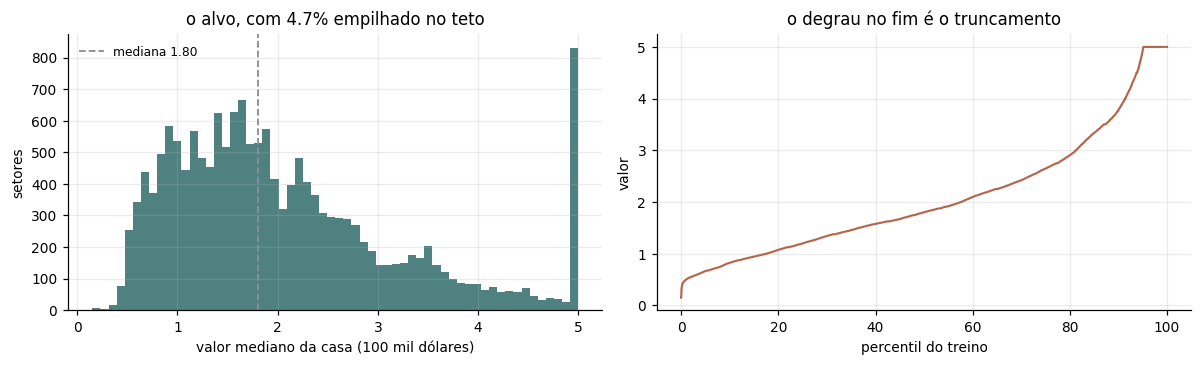

In [14]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))

_teto = y_todos.max()
_no_teto = float((y_todos >= _teto - 1e-6).mean())
print("O TETO DO ALVO\n")
print(f"  o valor máximo é {_teto:.5f} e {_no_teto*100:.2f}% dos setores estão nele")
print(f"  o censo truncou tudo acima de 500 mil dólares nesse valor, então existe")
print(f"  uma massa artificial no topo que nenhum modelo consegue separar")
print(f"\n  assimetria do alvo: "
      f"{float(((y_train-y_train.mean())**3).mean()/y_train.std()**3):.3f}")

print("\n\nREFERÊNCIAS TRIVIAIS (MAE em unidades de 100 mil dólares)\n")
print(f"  chutar a média do treino   : {mae_media:.4f}   "
      f"({mae_media*100:.1f} mil dólares)")
print(f"  chutar a mediana do treino : {mae_mediana:.4f}   "
      f"({mae_mediana*100:.1f} mil dólares)")
_ep = float(np.abs(y_test - np.median(y_train)).std() / np.sqrt(len(y_test)))
print(f"\n  erro padrão do MAE com {len(y_test):,} exemplos de teste: {_ep:.4f}")
print(f"  diferenças menores que isso não são distinguíveis")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(y_train, bins=60, color=COR_KAL, alpha=.85)
ax[0].axvline(np.median(y_train), color=COR_REF, ls="--", lw=1.2,
              label=f"mediana {np.median(y_train):.2f}")
ax[0].set(xlabel="valor mediano da casa (100 mil dólares)", ylabel="setores",
          title=f"o alvo, com {_no_teto*100:.1f}% empilhado no teto")
ax[0].legend(frameon=False, fontsize=8)
_o = np.argsort(y_train)
ax[1].plot(np.arange(len(y_train))/len(y_train)*100, y_train[_o], color=COR_REW, lw=1.4)
ax[1].set(xlabel="percentil do treino", ylabel="valor",
          title="o degrau no fim é o truncamento")
plt.tight_layout(); plt.show()


## 3.3 Como são os números

In [15]:
N_HEAD = 5
print(f"CADA LINHA É UM SETOR CENSITÁRIO: 1 alvo + {N_ATRIB} atributos\n")
print(f"O ALVO (y), as {N_HEAD} primeiras linhas do treino\n")
print("   " + "".join(f"{v:>9.3f}" for v in y_train[:N_HEAD]))
print("   valor mediano da casa em unidades de 100 mil dólares.")
print("   Não é binarizado e não entra na retina.")

print(f"\n\nOS {N_ATRIB} ATRIBUTOS, as {N_HEAD} primeiras linhas\n")
print("   " + "".join(f"{n[:10]:>12}" for n in NOMES_ATRIB))
for i in range(N_HEAD):
    print("   " + "".join(f"{X_train[i, j]:>12.3f}" for j in range(N_ATRIB)))

print(f"\n\nATRIBUTO A ATRIBUTO, sobre os {N_TREINO:,} setores do treino\n")
print(f"   {'atributo':>12}{'menor':>11}{'p1':>10}{'mediana':>11}{'p99':>11}"
      f"{'maior':>12}{'desvio':>10}{'p99-p1 / faixa':>17}")
for j, nome in enumerate(NOMES_ATRIB):
    c = X_train[:, j]
    p1, p99 = np.percentile(c, [1, 99])
    conc = (p99 - p1) / (c.max() - c.min() + 1e-12)
    print(f"   {nome:>12}{c.min():>11.3f}{p1:>10.3f}{np.median(c):>11.3f}"
          f"{p99:>11.3f}{c.max():>12.3f}{c.std():>10.3f}{conc:>17.3f}")

print(f"\n   a última coluna diz quanto da faixa total os 98% centrais ocupam.")
print(f"   Perto de 1 o atributo é bem distribuído; perto de 0 ele tem cauda longa,")
print(f"   e aí o termômetro linear gasta bits em regiões sem dado.")


CADA LINHA É UM SETOR CENSITÁRIO: 1 alvo + 8 atributos

O ALVO (y), as 5 primeiras linhas do treino

       5.000    2.700    1.961    1.188    2.250
   valor mediano da casa em unidades de 100 mil dólares.
   Não é binarizado e não entra na retina.


OS 8 ATRIBUTOS, as 5 primeiras linhas

         MedInc    HouseAge    AveRooms   AveBedrms  Population    AveOccup    Latitude   Longitude
          4.239       6.000       7.723       1.169     228.000       3.508      33.830    -117.550
          4.390      52.000       5.327       1.101    1485.000       3.322      37.730    -122.440
          3.933      26.000       4.668       1.046    1022.000       2.777      33.830    -118.000
          1.465      38.000       3.383       1.010     749.000       3.636      34.010    -118.260
          3.176      52.000       4.120       1.043    1135.000       1.970      34.080    -118.360


ATRIBUTO A ATRIBUTO, sobre os 16,512 setores do treino

       atributo      menor        p1    mediana    

## 3.4 Latitude e longitude

A preocupação natural é que latitude sozinha diga pouco e longitude sozinha
também, sendo o par que localiza. Mas o endereço de uma RAM node é a
**conjunção** dos bits sorteados, então quando o sorteio pega um bit de cada uma
aquele endereço passa a representar um retângulo no mapa. A célula abaixo mede
com que frequência isso acontece, e por isso as duas entram como atributos
contínuos comuns, sem tratamento especial.

In [16]:
# Latitude e longitude entram como dois atributos contínuos comuns, sem
# tratamento especial. A justificativa é que o endereço de uma RAM node é a
# conjunção dos bits sorteados, então quando o sorteio pega um bit de cada uma
# aquele endereço passa a representar um retângulo no mapa. Esta célula mede
# com que frequência isso acontece.
_i_lat = NOMES_ATRIB.index("Latitude")
_i_lon = NOMES_ATRIB.index("Longitude")
_REP = 200

print(f"RAM NODES QUE ENXERGAM LATITUDE E LONGITUDE JUNTAS")
print(f"({_REP} sorteios de mapping; elas são 2 dos {N_ATRIB} atributos)\n")
print(f"{'therm':>7}{'retina':>9}{'addr':>6}{'rams':>7}"
      f"{'só uma delas':>15}{'as duas juntas':>17}")
_rng = np.random.default_rng(0)
for t in (50, 100, 150):
    bits = t * N_ATRIB
    dono = np.repeat(np.arange(N_ATRIB), t)
    for a in (4, 6, 12, 20):
        nr = bits // a
        if nr < 2:
            continue
        so, amb = [], []
        for _ in range(_REP):
            m = _rng.permutation(bits)[:nr * a].reshape(nr, a)
            d = dono[m]
            lat, lon = (d == _i_lat).any(1), (d == _i_lon).any(1)
            amb.append((lat & lon).mean()); so.append((lat ^ lon).mean())
        print(f"{t:>7}{bits:>9}{a:>6}{nr:>7}"
              f"{np.mean(so)*100:>14.1f}%{np.mean(amb)*100:>16.1f}%")
print("\nA fração não depende do tamanho do termômetro, só da razão entre o")
print("address size e o número de atributos, porque cada atributo ocupa 1/8 da retina.")


RAM NODES QUE ENXERGAM LATITUDE E LONGITUDE JUNTAS
(200 sorteios de mapping; elas são 2 dos 8 atributos)

  therm   retina  addr   rams   só uma delas   as duas juntas
     50      400     4    100          54.2%            14.2%
     50      400     6     66          54.7%            28.0%
     50      400    12     33          32.9%            64.2%
     50      400    20     20          12.3%            87.5%
    100      800     4    200          54.0%            14.5%
    100      800     6    133          54.2%            28.2%
    100      800    12     66          33.6%            63.4%
    100      800    20     40          12.5%            87.2%
    150     1200     4    300          53.8%            14.5%
    150     1200     6    200          54.1%            28.2%
    150     1200    12    100          33.7%            63.2%
    150     1200    20     60          13.2%            86.5%

A fração não depende do tamanho do termômetro, só da razão entre o
address size e o núm

## 3.5 O tamanho da retina com 8 atributos

Este é o ponto que mais muda em relação ao notebook 08. Lá eram 90 atributos e
um termômetro de 20 bits já dava 1.800 bits de retina. Aqui são 8, então o mesmo
termômetro 20 daria 160 bits e, com address 20, apenas 8 RAM nodes.

In [17]:
# Com 8 atributos a retina é 8 x therm, e não 90 x therm como no
# YearPredictionMSD. Isso muda a escala do termômetro: para chegar em algumas
# centenas de RAM nodes é preciso 50 a 150 bits por atributo, não 20.
print(f"TAMANHO DA RETINA E NÚMERO DE RAM NODES, com {N_ATRIB} atributos\n")
_ADDRS = (4, 6, 8, 12, 20)
print(f"{'therm':>7}{'retina':>9}" + "".join(f"{'addr '+str(a):>10}" for a in _ADDRS))
for t in (20, 30, 50, 100, 150, 200):
    print(f"{t:>7}{t*N_ATRIB:>9}"
          + "".join(f"{t*N_ATRIB//a:>10}" for a in _ADDRS))
print(f"\nCom termômetro 20, que venceu no YearPredictionMSD, address 20 daria")
print(f"{20*N_ATRIB//20} RAM nodes. A predição viraria a média de {20*N_ATRIB//20} células.")


TAMANHO DA RETINA E NÚMERO DE RAM NODES, com 8 atributos

  therm   retina    addr 4    addr 6    addr 8   addr 12   addr 20
     20      160        40        26        20        13         8
     30      240        60        40        30        20        12
     50      400       100        66        50        33        20
    100      800       200       133       100        66        40
    150     1200       300       200       150       100        60
    200     1600       400       266       200       133        80

Com termômetro 20, que venceu no YearPredictionMSD, address 20 daria
8 RAM nodes. A predição viraria a média de 8 células.


---
# Seção 4 — Regression WiSARD

Quatro eixos no grid: tipo de termômetro, tamanho do termômetro, address size e
média. As seis médias saem do mesmo ajuste, porque a média só age na predição,
então o custo é o número de configurações de codificação e não o produto delas
pelas médias.

A memória do modelo é registrada por configuração: células ocupadas vezes 24
bytes, que é a chave mais contador e soma, mais o mapping da retina e os
limiares do termômetro. O `simple` guarda um vetor de limiares só, enquanto os
outros dois guardam um por atributo, e isso entra na conta.

In [18]:
# ═══════════════ VARREDURA DA REGRESSION WISARD ═════════════════════════════
# Quatro eixos: tipo de termômetro, tamanho do termômetro, address size e média.
# As seis médias saem do MESMO ajuste, porque a média só age na predição.
REW_TERM  = ["simple", "dynamic", "distributive"]
REW_THERM = [50, 100, 150]
REW_ADDR  = [4, 6, 12]

REW_MEDIAS = ["SimpleMean", "PowerMean(2)", "HarmonicMean",
              "HarmonicPower(2)", "ExponentialMean", "Median"]
REW_ARQ = "grid_rew_california.csv"
# ════════════════════════════════════════════════════════════════════════════

_pares_rew = [(tp, t, a) for tp in REW_TERM for t in REW_THERM for a in REW_ADDR]
print(f"{len(_pares_rew)} configurações de codificação x {len(REW_MEDIAS)} médias "
      f"= {len(_pares_rew)*len(REW_MEDIAS)} linhas")
print(f"{len(_pares_rew)} ajustes, porque as médias são de graça\n")
print(f"{'termômetro':>14}{'therm':>7}{'addr':>6}{'retina':>9}{'rams':>7}")
for tp, t, a in _pares_rew:
    print(f"{tp:>14}{t:>7}{a:>6}{t*N_ATRIB:>9}{t*N_ATRIB//a:>7}")

linhas_rew, t0 = [], time.perf_counter()
ss_tot = float(np.sum((y_test - y_test.mean()) ** 2))
_medias_rew = medias_rew()

for k_, (tp, t, a) in enumerate(_pares_rew, 1):
    enc = TERMOMETROS[tp](X_train, t)
    Xb_tr, Xb_te = apply_encoders(X_train, enc), apply_encoders(X_test, enc)
    mapa = sorteia_mapping(Xb_tr.shape[1], a, seed=SEED_MAPPING)
    ret = Retina(a, mapa)
    idx = IndiceRK(ret, ret.enderecos(Xb_tr))          # só para contar células
    mem = idx.n_celulas * 24 + ret.mapping.nbytes + bytes_limiares(enc)

    for nome, m in _medias_rew.items():
        pr = RegressionWiSARD(a, m, mapa).fit(Xb_tr, y_train).predict(Xb_te)
        nf = int((~np.isfinite(pr)).sum())
        if nf:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        linhas_rew.append(dict(termometro=tp, therm=t, address=a, n_rams=ret.n_rams,
                               celulas=idx.n_celulas, memoria_bytes=mem, media=nome,
                               MAE=mean_absolute_error(y_test, pr),
                               RMSE=float(np.sqrt(mean_squared_error(y_test, pr))),
                               R2=1.0 - float(np.sum((y_test - pr) ** 2)) / ss_tot,
                               nao_finito=nf))
    el = time.perf_counter() - t0
    print(f"  {k_:>2}/{len(_pares_rew)}  {tp:<13} therm {t:>3} addr {a:>2}  "
          f"{idx.n_celulas:>8,} células  {el/60:>5.1f} min  "
          f"faltam ~{el/k_*(len(_pares_rew)-k_)/60:.0f} min")
    del Xb_tr, Xb_te, ret, idx

grid_rew = pd.DataFrame(linhas_rew).sort_values("MAE").reset_index(drop=True)
grid_rew.to_csv(REW_ARQ, index=False)
REW_MELHOR = grid_rew.loc[0].to_dict()
print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min, "
      f"{len(grid_rew)} linhas em {REW_ARQ}")


27 configurações de codificação x 6 médias = 162 linhas
27 ajustes, porque as médias são de graça

    termômetro  therm  addr   retina   rams
        simple     50     4      400    100
        simple     50     6      400     66
        simple     50    12      400     33
        simple    100     4      800    200
        simple    100     6      800    133
        simple    100    12      800     66
        simple    150     4     1200    300
        simple    150     6     1200    200
        simple    150    12     1200    100
       dynamic     50     4      400    100
       dynamic     50     6      400     66
       dynamic     50    12      400     33
       dynamic    100     4      800    200
       dynamic    100     6      800    133
       dynamic    100    12      800     66
       dynamic    150     4     1200    300
       dynamic    150     6     1200    200
       dynamic    150    12     1200    100
  distributive     50     4      400    100
  distributive     50

## 4.2 O resultado da ReW

In [19]:
if "grid_rew" not in globals():
    grid_rew = pd.read_csv(REW_ARQ).sort_values("MAE").reset_index(drop=True)
    REW_MELHOR = grid_rew.loc[0].to_dict()

print("AS 12 MELHORES\n")
print(grid_rew.head(12)[["termometro", "therm", "address", "n_rams", "media",
                         "MAE", "R2", "memoria_bytes"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

print(f"\n\nMELHOR MAE POR TIPO DE TERMÔMETRO\n")
print(grid_rew.groupby("termometro").MAE.min().sort_values()
      .to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nMELHOR MAE POR MÉDIA\n")
print(grid_rew.groupby("media").MAE.min().sort_values()
      .to_string(float_format=lambda v: f"{v:.4f}"))
print(f"\nMELHOR MAE POR (termômetro, therm, address)\n")
_t = (grid_rew.groupby(["termometro", "therm", "address"])
      .agg(MAE=("MAE", "min"), KB=("memoria_bytes", lambda s: s.iloc[0] / 1024),
           celulas=("celulas", "first")).reset_index().sort_values("MAE"))
print(_t.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

print(f"\n\nVENCEDOR DA ReW\n")
for c_ in ["termometro", "therm", "address", "n_rams", "celulas", "media"]:
    print(f"  {c_:<12} = {REW_MELHOR[c_]}")
print(f"  MAE        = {REW_MELHOR['MAE']:.4f}   R2 = {REW_MELHOR['R2']:.4f}")
print(f"  memória    = {REW_MELHOR['memoria_bytes']/1024:,.1f} KB")
print(f"\n  chutar a média do treino: {mae_media:.4f}")
print(f"  chutar a mediana        : {mae_mediana:.4f}")


AS 12 MELHORES

  termometro  therm  address  n_rams            media    MAE     R2  memoria_bytes
distributive     50       12      33 HarmonicPower(2) 0.5633 0.5277         297896
distributive     50       12      33     HarmonicMean 0.5644 0.5439         297896
distributive     50       12      33           Median 0.5727 0.5629         297896
distributive    150       12     100 HarmonicPower(2) 0.5774 0.5058         819120
distributive    100       12      66 HarmonicPower(2) 0.5791 0.5013         533152
distributive    150       12     100     HarmonicMean 0.5792 0.5221         819120
distributive    100       12      66     HarmonicMean 0.5818 0.5164         533152
distributive    150       12     100           Median 0.5834 0.5394         819120
distributive     50       12      33     PowerMean(2) 0.5892 0.5581         297896
distributive    100       12      66           Median 0.5932 0.5242         533152
distributive     50       12      33  ExponentialMean 0.5969 0.5660    

---
# Seção 5 — Modelos de comparação

Os mesmos quatro do notebook 08, com a memória de cada um. Eles usam os 8
atributos contínuos direto, sem termômetro e sem retina.

In [20]:
# ═══════════════ MODELOS DE COMPARAÇÃO ══════════════════════════════════════
USAR = ["regressão linear", "SVR (RBF)", "decision tree", "gradient boosting"]
SVR_MAX_TREINO = 20_000        # acima disso o SVR é ajustado numa subamostra
SEED_BASELINE  = 0

PARAMS = {
    "SVR (RBF)":         dict(kernel="rbf", C=10.0, epsilon=0.1, gamma="scale",
                              cache_size=500),
    "decision tree":     dict(max_depth=12, min_samples_leaf=20,
                              random_state=SEED_BASELINE),
    "gradient boosting": dict(max_iter=400, max_depth=6, learning_rate=0.08,
                              l2_regularization=1.0, early_stopping=False,
                              random_state=SEED_BASELINE),
}
ARQ_BASE = "baselines_california.csv"
# ════════════════════════════════════════════════════════════════════════════

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor

# O gradient boosting é o HistGradientBoostingRegressor do sklearn, mesma
# família do XGBoost. O SVR é o único que precisa de escala em X e em y, porque
# C e epsilon são definidos nas unidades do alvo; por isso, e só nele, entra o
# TransformedTargetRegressor. Árvores e mínimos quadrados são invariantes.


def constroi(nome):
    if nome == "regressão linear":
        return LinearRegression(), None
    if nome == "SVR (RBF)":
        return TransformedTargetRegressor(
            regressor=make_pipeline(StandardScaler(), SVR(**PARAMS[nome])),
            transformer=StandardScaler()), SVR_MAX_TREINO
    if nome == "decision tree":
        return DecisionTreeRegressor(**PARAMS[nome]), None
    if nome == "gradient boosting":
        return HistGradientBoostingRegressor(**PARAMS[nome]), None
    raise ValueError(nome)


def bytes_modelo(est):
    """Bytes dos parâmetros que precisam ficar guardados para predizer."""
    if isinstance(est, TransformedTargetRegressor):
        return bytes_modelo(est.regressor_) + bytes_modelo(est.transformer_)
    if hasattr(est, "steps"):
        return sum(bytes_modelo(p) for _, p in est.steps)
    if isinstance(est, StandardScaler):
        return est.mean_.nbytes + est.scale_.nbytes
    if isinstance(est, LinearRegression):
        return est.coef_.nbytes + np.asarray(est.intercept_).nbytes
    if isinstance(est, SVR):
        return (est.support_vectors_.nbytes + est.dual_coef_.nbytes
                + est._intercept_.nbytes)
    if isinstance(est, DecisionTreeRegressor):
        t_ = est.tree_
        return (t_.children_left.nbytes + t_.children_right.nbytes + t_.feature.nbytes
                + t_.threshold.nbytes + t_.value.nbytes)
    if isinstance(est, HistGradientBoostingRegressor):
        return sum(pr.nodes.nbytes for etapa in est._predictors for pr in etapa)
    raise TypeError(type(est))


ss_tot_b = float(np.sum((y_test - y_test.mean()) ** 2))
rng_b = np.random.default_rng(SEED_BASELINE)
linhas_b = []
for nome in USAR:
    est, teto = constroi(nome)
    Xf, yf, obs = X_train, y_train, ""
    if teto is not None and teto < len(X_train):
        sel = np.sort(rng_b.choice(len(X_train), teto, replace=False))
        Xf, yf, obs = X_train[sel], y_train[sel], f"subamostra de {teto:,}"
    t0 = time.perf_counter(); est.fit(Xf, yf); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = np.asarray(est.predict(X_test), dtype=float)
    t_pred = time.perf_counter() - t0
    linhas_b.append({"modelo": nome, "n_treino": len(Xf),
                     "MAE": mean_absolute_error(y_test, pred),
                     "RMSE": float(np.sqrt(mean_squared_error(y_test, pred))),
                     "R2": 1.0 - float(np.sum((y_test - pred) ** 2)) / ss_tot_b,
                     "bytes": bytes_modelo(est),
                     "s_fit": t_fit, "s_pred": t_pred, "obs": obs})
    print(f"{nome:<20} MAE {linhas_b[-1]['MAE']:>7.4f}   "
          f"memória {linhas_b[-1]['bytes']/1024:>10,.1f} KB   "
          f"fit {t_fit:>6.1f}s   {obs}")

base_df = pd.DataFrame(linhas_b).sort_values("MAE").reset_index(drop=True)
base_df.to_csv(ARQ_BASE, index=False)
print(f"\n{len(base_df)} modelos, salvos em {ARQ_BASE}\n")
print(base_df[["modelo", "n_treino", "MAE", "RMSE", "R2", "bytes", "obs"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.4f}"))


regressão linear     MAE  0.5351   memória        0.1 KB   fit    0.0s   
SVR (RBF)            MAE  0.3652   memória      841.2 KB   fit   37.2s   
decision tree        MAE  0.4121   memória       41.7 KB   fit    0.1s   
gradient boosting    MAE  0.2921   memória    1,298.5 KB   fit    2.1s   

4 modelos, salvos em baselines_california.csv

           modelo  n_treino    MAE   RMSE     R2   bytes obs
gradient boosting     16512 0.2921 0.4416 0.8505 1329664    
        SVR (RBF)     16512 0.3652 0.5461 0.7713  861416    
    decision tree     16512 0.4121 0.6144 0.7105   42680    
 regressão linear     16512 0.5351 0.7273 0.5943      72    


---
# Seção 6 — R-KalWeNN

A codificação fica em aberto: preencha `KAL_TERM`, `KAL_THERM` e `KAL_ADDR` com
o que você escolher olhando a seção 4. Deixando as listas vazias, ele herda a
configuração vencedora da ReW.

**As faixas do Kalman.** Só as razões `p0/r` e `q/r` importam, então o `r` fica
fixo dos dois lados e a varredura anda em `p0` e `q`.

No `c`, o `p0_c` entre 0,01 e 1 é a faixa em que a confiança se espalha por
`[0,1]` ao longo das visitas. Acima de 1 ela satura já na primeira visita e
deixa de separar as células. O `q_c` acelera a saturação, então fica pequeno.

No `y`, o `r_y` é a variância de uma observação em torno do valor da célula.
Como a variância entre células costuma ser pequena, ela fica perto da variância
total do alvo, que é **medida** com `y_train.var()` em vez de chutada. O `p0_y`
e o `q_y` entram como razões de `r_y`, o que torna a grade transferível para o
AirFoil depois sem reescalar nada.

O `x0_y` vai para a mediana do treino, pelo mesmo motivo do notebook 08: com
`x0_y = 0` a célula precisaria percorrer toda a escala do alvo e a maioria
recebe poucas visitas.

Uma coisa a ter em mente ao ler o resultado, anotada no `Literatura` como
trabalho futuro: o `q_y` fixa uma janela efetiva de aproximadamente `1/K*`
exemplos, e o address size determina quantas visitas cada célula recebe. Os dois
não são independentes, e a varredura ainda procura um `q_y` único para todos os
address sizes.

In [21]:
# ═══════════════ VARREDURA DO R-KalWeNN ═════════════════════════════════════
# Codificação: preencha com o que você escolher olhando a seção 4.
# Vazio significa "use o vencedor da ReW".
KAL_TERM  = ["distributive"]      # ex.: ["distributive"]
KAL_THERM = [50]      # ex.: [100, 150]
KAL_ADDR  = [6, 12]      # ex.: [6, 12]

# ── Kalman do c ──────────────────────────────────────────────────────────────
# Só a razão p0/r importa, então r fica fixo. p0_c entre 0,01 e 1 é a faixa em
# que o c se espalha por [0,1] ao longo das visitas; acima disso ele satura na
# primeira visita e deixa de separar as células. q_c acelera a saturação, então
# fica pequeno.
KAL_R_C  = 1.0
KAL_P0_C = [0.01, 0.1, 1.0]
KAL_Q_C  = [1e-6, 1e-3]

# ── Kalman do y ──────────────────────────────────────────────────────────────
# r_y é a variância de uma observação em torno do valor da célula. Como a
# variância ENTRE células é pequena, ela fica perto da variância total do alvo,
# que é medida aqui e não chutada. p0_y e q_y entram como razões de r_y, o que
# torna a grade transferível para outros datasets.
KAL_R_Y     = float(y_train.var())
KAL_P0_Y_R  = [0.05, 0.2, 1.0, 10.0, 100.0]     # p0_y / r_y
KAL_Q_Y_R   = [0.001, 0.01, 0.1]                # q_y  / r_y

KAL_MEDIAS = ["K-SimpleMean", "K-PowerMean(2)", "K-HarmonicMean",
              "K-HarmonicPower(2)", "K-ExponentialMean", "K-Median"]
KAL_SEEDS  = (0,)
KAL_ARQ    = "grid_kalwenn_california.csv"
# ════════════════════════════════════════════════════════════════════════════

_tm = KAL_TERM  or [REW_MELHOR["termometro"]]
_th = KAL_THERM or [int(REW_MELHOR["therm"])]
_ad = KAL_ADDR  or [int(REW_MELHOR["address"])]
_pares_kal = [(tp, t, a) for tp in _tm for t in _th for a in _ad]
_combos_kal = list(product(KAL_P0_C, KAL_Q_C, KAL_P0_Y_R, KAL_Q_Y_R))
X0_C, X0_Y = 0.0, float(np.median(y_train))

print(f"codificação: {_pares_kal}"
      + ("   (herdada do vencedor da ReW)" if not KAL_TERM else ""))
print(f"x0_c {X0_C}, x0_y {X0_Y:.4f} (mediana do treino), r_c {KAL_R_C}, "
      f"r_y {KAL_R_Y:.4f} (variância do alvo)")
print(f"{len(_combos_kal)} combinações x {len(_pares_kal)} codificações x "
      f"{len(KAL_SEEDS)} seed = {len(_combos_kal)*len(_pares_kal)*len(KAL_SEEDS)} ajustes")
print(f"as {len(KAL_MEDIAS)} médias saem do mesmo ajuste\n")

linhas_kal, t0 = [], time.perf_counter()
for tp, t, a in _pares_kal:
    enc = TERMOMETROS[tp](X_train, t)
    Xb_tr, Xb_te = apply_encoders(X_train, enc), apply_encoders(X_test, enc)
    ret = Retina(a, sorteia_mapping(Xb_tr.shape[1], a, seed=SEED_MAPPING))
    idx = IndiceRK(ret, ret.enderecos(Xb_tr))
    sl_te = idx.slots(ret.enderecos(Xb_te))
    mem = idx.n_celulas * 24 + ret.mapping.nbytes + bytes_limiares(enc)
    print(f"{tp} therm {t} addr {a}: {ret.n_rams} RAM nodes, {idx.n_celulas:,} células, "
          f"cobertura {(sl_te >= 0).mean()*100:.1f}%, memória {mem/1024:,.1f} KB")
    for p0c, qc, p0yr, qyr in _combos_kal:
        p0y, qy = p0yr * KAL_R_Y, qyr * KAL_R_Y
        acum = {m: [] for m in KAL_MEDIAS}
        for s in KAL_SEEDS:
            mod = RKalWeNN(a, ret.mapping.ravel(), q_c=qc, r_c=KAL_R_C, p0_c=p0c,
                           q_y=qy, r_y=KAL_R_Y, p0_y=p0y, x0_c=X0_C, x0_y=X0_Y,
                           seed=s, indice=idx).fit(y=y_train)
            for nome, v in avalia(mod, sl_te, y_test, KAL_MEDIAS).items():
                acum[nome].append(v)
        for nome, vs in acum.items():
            arr = np.array([v[:3] for v in vs], dtype=float)
            linhas_kal.append(dict(termometro=tp, therm=t, address=a,
                                   n_rams=ret.n_rams, celulas=idx.n_celulas,
                                   memoria_bytes=mem, media=nome,
                                   p0_c=p0c, q_c=qc, p0_y_r=p0yr, q_y_r=qyr,
                                   p0_y=p0y, q_y=qy,
                                   MAE=arr[:, 0].mean(), RMSE=arr[:, 1].mean(),
                                   R2=arr[:, 2].mean(),
                                   nao_finito=int(max(v[3] for v in vs))))
    print(f"  parcial: {(time.perf_counter()-t0)/60:.1f} min")
    del Xb_tr, Xb_te, ret, idx, sl_te

grid_kal = pd.DataFrame(linhas_kal).sort_values("MAE").reset_index(drop=True)
grid_kal.to_csv(KAL_ARQ, index=False)
KAL_MELHOR = grid_kal.loc[0].to_dict()
print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min, "
      f"{len(grid_kal):,} linhas em {KAL_ARQ}\n")
print("AS 10 MELHORES\n")
print(grid_kal.head(10)[["termometro", "therm", "address", "media",
                         "p0_c", "q_c", "p0_y_r", "q_y_r", "MAE", "R2"]]
      .to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nmelhor por média\n")
print(grid_kal.groupby("media").MAE.min().sort_values()
      .to_string(float_format=lambda v: f"{v:.4f}"))


codificação: [('distributive', 50, 6), ('distributive', 50, 12)]
x0_c 0.0, x0_y 1.8025 (mediana do treino), r_c 1.0, r_y 1.3384 (variância do alvo)
90 combinações x 2 codificações x 1 seed = 180 ajustes
as 6 médias saem do mesmo ajuste

distributive therm 50 addr 6: 66 RAM nodes, 2,409 células, cobertura 100.0%, memória 62.7 KB
  parcial: 0.9 min
distributive therm 50 addr 12: 33 RAM nodes, 12,147 células, cobertura 99.7%, memória 290.9 KB
  parcial: 1.7 min

concluído em 1.7 min, 1,080 linhas em grid_kalwenn_california.csv

AS 10 MELHORES

  termometro  therm  address    media  p0_c   q_c  p0_y_r  q_y_r    MAE     R2
distributive     50       12 K-Median     1 0.001     100    0.1 0.5585 0.5686
distributive     50       12 K-Median     1 1e-06     100    0.1 0.5585 0.5686
distributive     50       12 K-Median     1 0.001      10    0.1 0.5586 0.5684
distributive     50       12 K-Median     1 1e-06      10    0.1 0.5586 0.5684
distributive     50       12 K-Median     1 0.001       1 

---
# Seção 7 — Gráficos

Três comparações. A primeira é sobre a codificação, a segunda sobre os
hiperparâmetros do filtro, e a terceira põe todos os modelos lado a lado.

## 7.1 Termômetro e address contra memória e MAE

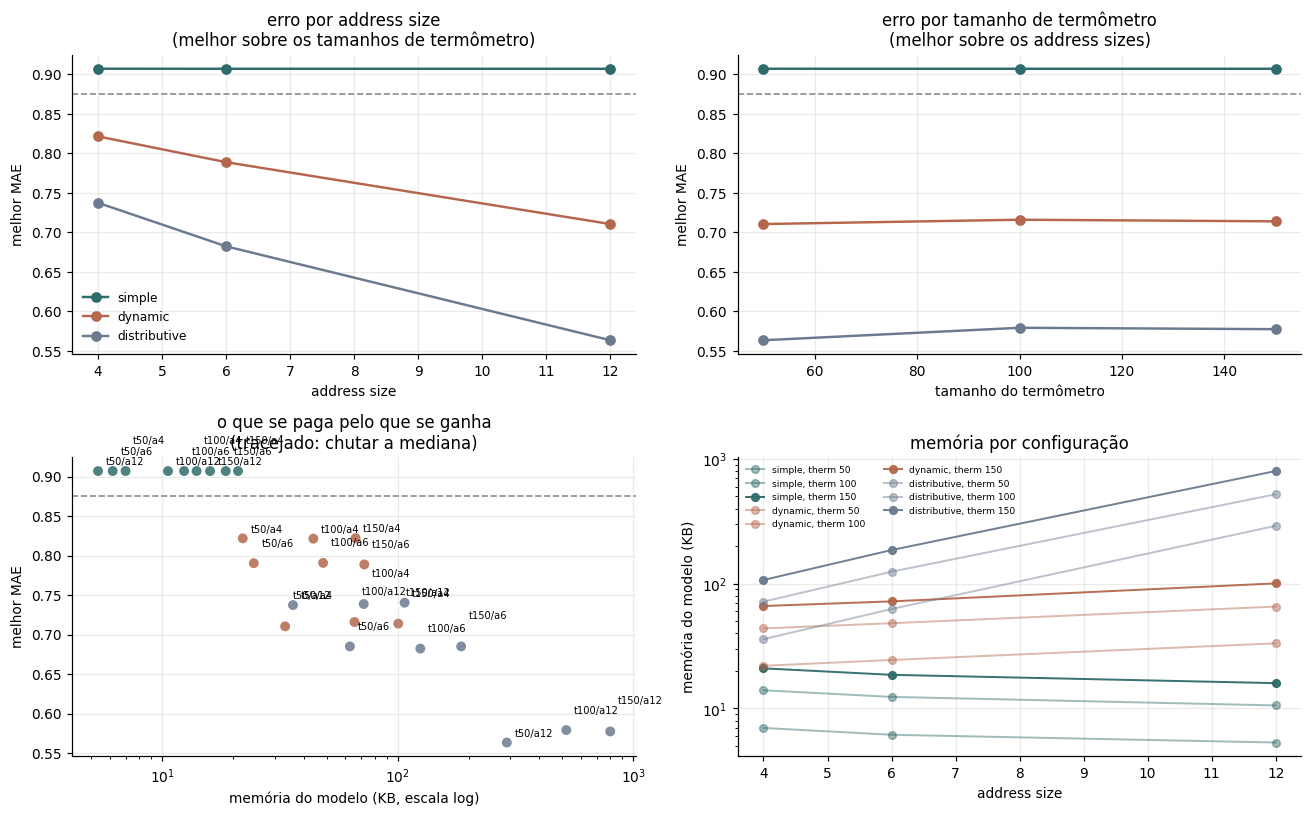

MELHOR MAE E MEMÓRIA POR CONFIGURAÇÃO DE CODIFICAÇÃO

  termometro  therm  address  n_rams  celulas      KB   MAE
distributive     50       12      33    12147 290.914 0.563
distributive    150       12     100    33330 799.922 0.577
distributive    100       12      66    21684 520.656 0.579
distributive    100        6     133     4793 124.820 0.682
distributive     50        6      66     2409  62.680 0.685
distributive    150        6     200     7141 186.117 0.685
     dynamic     50       12      33     1154  33.266 0.710
     dynamic    150       12     100     3491 100.570 0.714
     dynamic    100       12      66     2266  65.547 0.716
distributive     50        4     100     1266  35.922 0.737
distributive    100        4     200     2529  71.773 0.739
distributive    150        4     300     3768 107.062 0.740
     dynamic    150        6     200     2279  72.164 0.789
     dynamic     50        6      66      779  24.477 0.790
     dynamic    100        6     133     1525 

In [22]:
# ═══════ GRÁFICO 1: termômetro e address contra memória e MAE (ReW) ═════════
if "grid_rew" not in globals():
    grid_rew = pd.read_csv(REW_ARQ).sort_values("MAE").reset_index(drop=True)

_cfg = (grid_rew.groupby(["termometro", "therm", "address"])
        .agg(MAE=("MAE", "min"), bytes=("memoria_bytes", "first"),
             celulas=("celulas", "first"), n_rams=("n_rams", "first"))
        .reset_index())
_cfg["KB"] = _cfg["bytes"] / 1024
_tipos = [t for t in REW_TERM if t in set(_cfg.termometro)]
_cor = {t: CORES_SERIE[i % len(CORES_SERIE)] for i, t in enumerate(_tipos)}

fig, ax = plt.subplots(2, 2, figsize=(12, 7.5))

for tp in _tipos:
    s = _cfg[_cfg.termometro == tp]
    m = s.groupby("address").MAE.min().reset_index()
    ax[0, 0].plot(m.address, m.MAE, "o-", color=_cor[tp], lw=1.6, ms=6, label=tp)
    m = s.groupby("therm").MAE.min().reset_index()
    ax[0, 1].plot(m.therm, m.MAE, "o-", color=_cor[tp], lw=1.6, ms=6, label=tp)
    for t_ in sorted(s.therm.unique()):
        u = s[s.therm == t_].sort_values("address")
        ax[1, 1].plot(u.address, u.KB, "o-", color=_cor[tp], lw=1.3, ms=5,
                      alpha=.45 + .5 * (t_ == s.therm.max()),
                      label=f"{tp}, therm {t_}")
    ax[1, 0].scatter(s.KB, s.MAE, s=42, color=_cor[tp], alpha=.85,
                     edgecolor="none", label=tp)
    for k_, (_, r_) in enumerate(s.sort_values("KB").iterrows()):
        # alterna o deslocamento para os rótulos não se empilharem quando os
        # pontos coincidem, o que acontece sempre que a codificação não muda nada
        ax[1, 0].annotate(f"t{int(r_.therm)}/a{int(r_.address)}", (r_.KB, r_.MAE),
                          fontsize=6.5, textcoords="offset points",
                          xytext=(5, 4 + 7 * (k_ % 3)))

for a_ in (ax[0, 0], ax[0, 1], ax[1, 0]):
    a_.axhline(mae_mediana, color=COR_REF, ls="--", lw=1.1)
ax[0, 0].set(xlabel="address size", ylabel="melhor MAE",
             title="erro por address size\n(melhor sobre os tamanhos de termômetro)")
ax[0, 1].set(xlabel="tamanho do termômetro", ylabel="melhor MAE",
             title="erro por tamanho de termômetro\n(melhor sobre os address sizes)")
ax[1, 0].set(xlabel="memória do modelo (KB, escala log)", xscale="log",
             ylabel="melhor MAE", title="o que se paga pelo que se ganha\n"
                                        "(tracejado: chutar a mediana)")
ax[1, 1].set(xlabel="address size", ylabel="memória do modelo (KB)", yscale="log",
             title="memória por configuração")
ax[0, 0].legend(frameon=False, fontsize=8)
ax[1, 1].legend(frameon=False, fontsize=6, ncol=2)
plt.tight_layout(); plt.show()

print("MELHOR MAE E MEMÓRIA POR CONFIGURAÇÃO DE CODIFICAÇÃO\n")
print(_cfg.sort_values("MAE")[["termometro", "therm", "address", "n_rams",
                               "celulas", "KB", "MAE"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.3f}"))


## 7.2 Os hiperparâmetros do R-KalWeNN

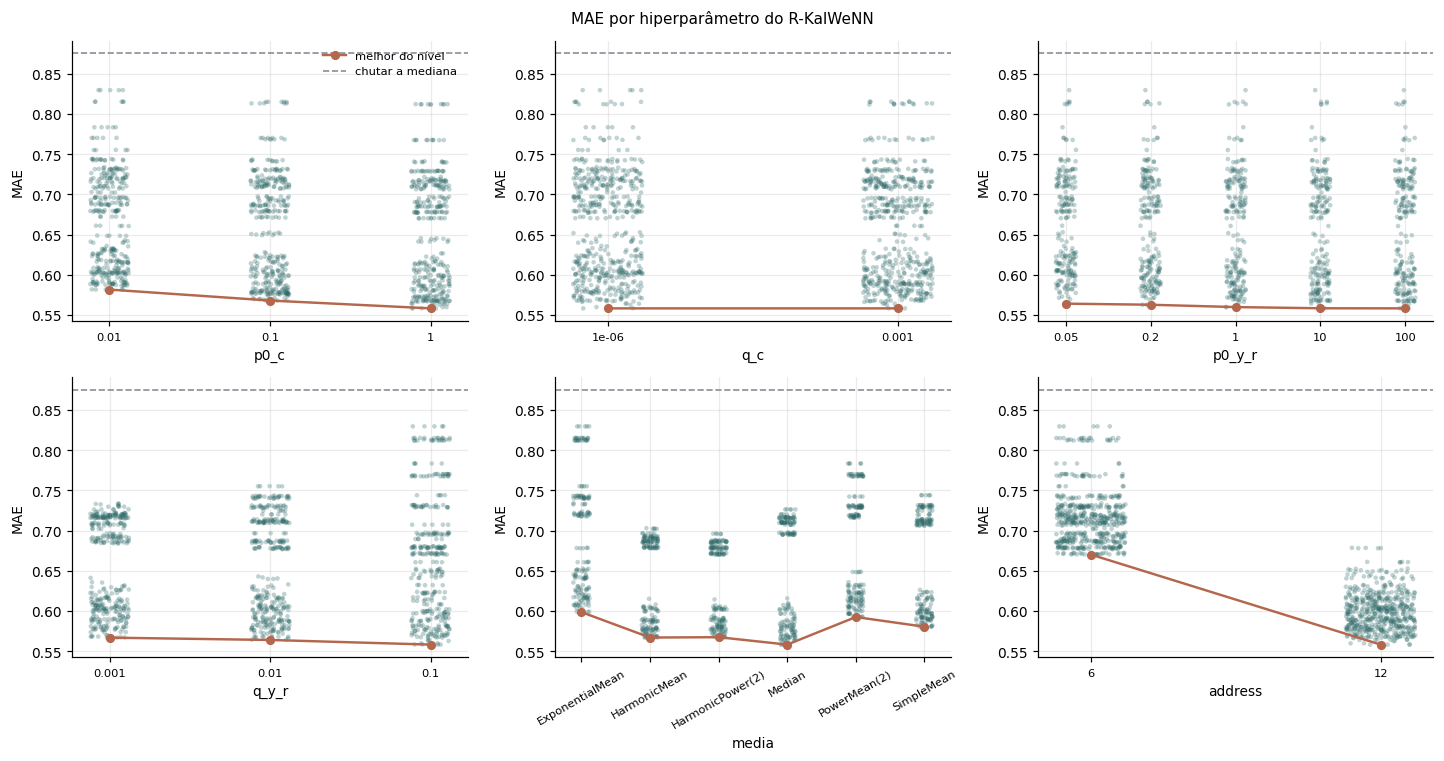

In [23]:
# ═══════ GRÁFICO 2: hiperparâmetros do R-KalWeNN contra o MAE ═══════════════
# Ponto claro = uma configuração rodada. Linha escura = melhor MAE de cada
# nível. Linha plana quer dizer que aquele eixo não está decidindo nada.
if "grid_kal" not in globals():
    grid_kal = pd.read_csv(KAL_ARQ).sort_values("MAE").reset_index(drop=True)

EIXOS_KAL = [c for c in ["p0_c", "q_c", "p0_y_r", "q_y_r", "media",
                         "address", "therm", "termometro"]
             if c in grid_kal.columns and grid_kal[c].nunique() > 1]
_n = len(EIXOS_KAL)
_lin = int(np.ceil(_n / 3))
fig, ax = plt.subplots(_lin, min(3, _n), figsize=(4.4 * min(3, _n), 3.5 * _lin),
                       squeeze=False)
_rng = np.random.default_rng(0)
for a_, col in zip(ax.ravel(), EIXOS_KAL):
    niveis = sorted(grid_kal[col].unique(), key=lambda v: (isinstance(v, str), v))
    pos = {v: i for i, v in enumerate(niveis)}
    x = grid_kal[col].map(pos).values
    a_.scatter(x + _rng.uniform(-.12, .12, len(x)), grid_kal["MAE"], s=9,
               alpha=.30, color=COR_KAL, edgecolor="none")
    a_.plot(range(len(niveis)),
            [grid_kal.loc[grid_kal[col] == v, "MAE"].min() for v in niveis],
            "o-", color=COR_REW, lw=1.6, ms=5, label="melhor do nível")
    a_.axhline(mae_mediana, color=COR_REF, ls="--", lw=1.1, label="chutar a mediana")
    a_.set(xticks=range(len(niveis)), ylabel="MAE", xlabel=col,
           xticklabels=[f"{v:g}" if not isinstance(v, str) else v.replace("K-", "")
                        for v in niveis])
    a_.tick_params(axis="x", labelrotation=30 if col in ("media", "termometro") else 0,
                   labelsize=7.5)
for a_ in ax.ravel()[_n:]:
    a_.axis("off")
ax[0, 0].legend(frameon=False, fontsize=7.5)
fig.suptitle("MAE por hiperparâmetro do R-KalWeNN", fontsize=10)
plt.tight_layout(); plt.show()


## 7.3 Todos os modelos, MAE contra memória

MAE E MEMÓRIA, teste com 4,128 setores

                modelo   MAE        KB
     gradient boosting 0.292 1,298.500
             SVR (RBF) 0.365   841.227
         decision tree 0.412    41.680
      regressão linear 0.535     0.070
  R-KalWeNN (K-Median) 0.558   290.914
ReW (HarmonicPower(2)) 0.563   290.914

  chutar a média do treino   0.9071
  chutar a mediana do treino 0.8755


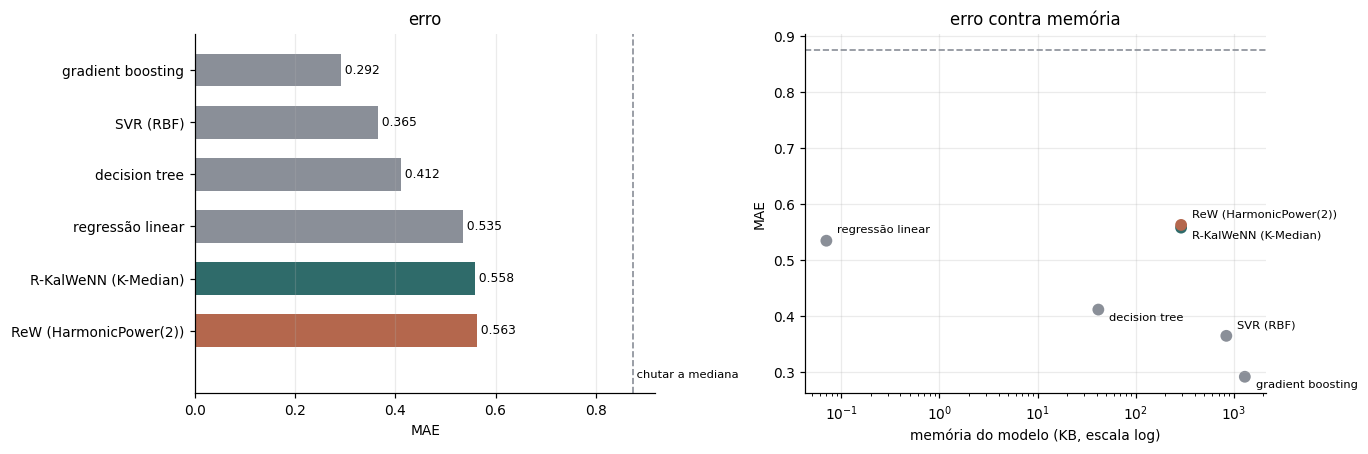

In [24]:
# ═══════ GRÁFICO 3: todos os modelos, MAE contra memória ════════════════════
comp = [(f"ReW ({REW_MELHOR['media']})", float(REW_MELHOR["MAE"]),
         float(REW_MELHOR["memoria_bytes"])),
        (f"R-KalWeNN ({KAL_MELHOR['media']})", float(KAL_MELHOR["MAE"]),
         float(KAL_MELHOR["memoria_bytes"]))]
for _, r_ in base_df.iterrows():
    comp.append((r_["modelo"] + (f" [{r_['obs']}]" if r_["obs"] else ""),
                 float(r_["MAE"]), float(r_["bytes"])))
comp = (pd.DataFrame(comp, columns=["modelo", "MAE", "bytes"])
        .sort_values("MAE").reset_index(drop=True))
comp["KB"] = comp["bytes"] / 1024

print(f"MAE E MEMÓRIA, teste com {len(y_test):,} setores\n")
print(comp[["modelo", "MAE", "KB"]]
      .to_string(index=False, float_format=lambda v: f"{v:,.3f}"))
print(f"\n  chutar a média do treino   {mae_media:.4f}")
print(f"  chutar a mediana do treino {mae_mediana:.4f}")

def _cor_modelo(n):
    return COR_KAL if "R-KalWeNN" in n else COR_REW if n.startswith("ReW") else COR_REF

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
o = comp.iloc[::-1]
ax[0].barh(np.arange(len(o)), o["MAE"], color=[_cor_modelo(n) for n in o.modelo],
           height=.62)
ax[0].axvline(mae_mediana, color=COR_REF, ls="--", lw=1.1)
ax[0].text(mae_mediana, -.85, " chutar a mediana", fontsize=7.5, va="center")
ax[0].set(yticks=np.arange(len(o)), yticklabels=o["modelo"], xlabel="MAE",
          ylim=(-1.2, len(o) - .3), title="erro")
ax[0].grid(axis="y", visible=False)
for i, v in enumerate(o["MAE"]):
    ax[0].text(v, i, f" {v:.3f}", va="center", fontsize=8)

ax[1].scatter(comp["KB"], comp["MAE"], s=60,
              color=[_cor_modelo(n) for n in comp.modelo], edgecolor="none")
for k_, (_, r_) in enumerate(comp.sort_values("KB").iterrows()):
    ax[1].annotate(r_["modelo"], (r_["KB"], r_["MAE"]), fontsize=7.5,
                   textcoords="offset points", xytext=(7, 5 - 12 * (k_ % 2)))
ax[1].axhline(mae_mediana, color=COR_REF, ls="--", lw=1.1)
ax[1].set(xscale="log", xlabel="memória do modelo (KB, escala log)", ylabel="MAE",
          title="erro contra memória")
plt.tight_layout(); plt.show()
